In [1]:
import numpy as np
import onnxruntime as ort
from PIL import Image

In [7]:
# 1. Load the exported ONNX model
onnx_model_path = r'D:\MTEC\Image-Processing\Cat and Dog Classification\cat_dog_classifier.onnx'
session = ort.InferenceSession(onnx_model_path)

# Get input details from the model
input_name = session.get_inputs()[0].name
print(f"Model Input Name: {input_name}")

Model Input Name: image_input:0


In [8]:
# 2. Load and preprocess the test image
image_path = r'D:\MTEC\Image-Processing\Cat and Dog Classification\dataset\Other\OIP-ZYzxmhrBXfvdySrXprqM5AHaE9.jpeg'  # Replace with your image path

In [9]:
with Image.open(image_path) as img:
    img = img.convert('RGB')
    img_array = np.array(img, dtype=np.float32)

In [10]:
# 3. Add batch dimension to match model input shape (Batch, Height, Width, Channels)
input_data = np.expand_dims(img_array, axis=0)

# 4. Run inference using ONNX Runtime
outputs = session.run(None, {input_name: input_data})
score = outputs[0][0][0]  # Sigmoid output score (0 to 1)

# 3. Add batch dimension to match model input shape (Batch, Height, Width, Channels)
input_data = np.expand_dims(img_array, axis=0)

# 4. Run inference using ONNX Runtime
outputs = session.run(None, {input_name: input_data})
probabilities = outputs[0][0]  # Array of 3 probabilities: [Cat, Dog, Other]

# 5. Interpret the prediction results
class_names = ['Cat', 'Dog', 'Other']
pred_class_idx = np.argmax(probabilities)
pred_class = class_names[pred_class_idx]
confidence = probabilities[pred_class_idx] * 100

print(f"Prediction: {pred_class} (Confidence: {confidence:.2f}%)")

Prediction: Other (Confidence: 97.97%)


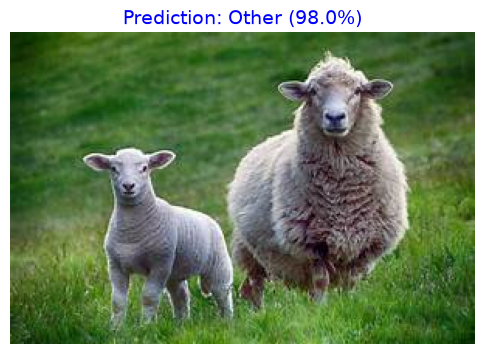

In [11]:
import matplotlib.pyplot as plt

# 6. Visualise the image along with the prediction result
plt.figure(figsize=(6, 6))
plt.imshow(img)
plt.axis('off')
plt.title(f"Prediction: {pred_class} ({confidence:.1f}%)", fontsize=14, color='blue')
plt.show()